<a href="https://colab.research.google.com/github/nwaryszak/APRAU/blob/Natalia/APRAU_Step1n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Imports, data loading and initial audit

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [37]:
df = pd.read_csv('dataset_grupo_06.csv')

In [38]:
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

Dataset shape

In [39]:
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns.")

#Check for duplicates
duplicate_rows = df.duplicated().sum()
print(f"Duploicate patient records found: {duplicate_rows}")

Dataset Shape: 2000 rows, 35 columns.
Duploicate patient records found: 0


In [40]:
#Display first rows
display(df.head())

,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,blood_pressure,sugar_consumption,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Mature,Male,Obese,Current,58,0.643678,30.159257,5.436598,256.000000,6.867758,141.000000,Moderate,No,Low,Yes,No,135.000000,Low,6.258795,17.642313,134.260845,88.969014,15.160000,8.588845,74.546479,64.420845,129.290141,Primary,Employed,134.260845,9.42,1.100955,129.996562,117.0,HT_HY
1,Mature,Male,Overweight,Never,54,0.597701,29.527706,5.405745,274.000000,7.095850,319.000000,Moderate,No,High,No,Yes,152.000000,High,14.283054,5.086877,134.392491,89.571104,14.884869,8.463026,74.056883,65.304892,129.050057,Tertiary,Retired,134.392491,9.42,1.090490,129.878090,113.0,HT
2,Senior,Female,Overweight,Never,80,0.896552,27.320000,4.500000,229.436364,7.166333,255.821429,High,No,High,No,Yes,146.571429,High,8.315218,12.488407,133.508306,89.088594,15.190698,8.721595,74.238095,64.516058,130.229236,Secondary,Unemployed,133.508306,9.42,1.154289,129.050057,80.0,HT
3,Senior,Male,Obese,Current,70,0.781609,35.130000,6.800000,226.554622,7.083442,253.848739,High,No,High,Yes,No,148.067227,Medium,6.814157,11.921159,134.283565,89.392758,15.059443,8.416435,74.185515,65.224513,129.091365,Tertiary,Unemployed,134.283565,9.42,1.409238,130.545353,280.0,DI_HT_HY
4,Mature,Male,Obese,Never,52,0.574713,30.060476,5.443154,165.000000,6.387091,231.000000,Low,No,High,No,No,170.000000,High,13.741749,5.612789,133.613102,89.417133,14.940649,8.514670,74.719485,64.268197,130.545353,Primary,Employed,133.613102,9.42,1.226389,129.050057,138.0,HT_HY


In [41]:
#data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age_level             2000 non-null   object 
 1   gender                2000 non-null   object 
 2   bmi_level             2000 non-null   object 
 3   smoking               2000 non-null   object 
 4   age                   2000 non-null   int64  
 5   age_normalized        2000 non-null   float64
 6   bmi                   2000 non-null   float64
 7   HbA1c_level           2000 non-null   float64
 8   cholesterol           2000 non-null   float64
 9   sleep_hours           2000 non-null   float64
 10  triglycerides         2000 non-null   float64
 11  physical_activity     2000 non-null   object 
 12  family_history        2000 non-null   object 
 13  stress_level          2000 non-null   object 
 14  low_hdl_cholesterol   2000 non-null   object 
 15  high_ldl_cholesterol 

In [42]:
#Structural audit
data_info = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Values': df.isnull().sum(),
    'Missing Percentage (%)': (df.isnull().sum() / len(df)) * 100,
    'Unique Values': df.nunique()
})
display(data_info)

,Data Type,Missing Values,Missing Percentage (%),Unique Values
age_level,object,0,0.0,4
gender,object,0,0.0,2
bmi_level,object,0,0.0,4
smoking,object,0,0.0,3
age,int64,0,0.0,64
age_normalized,float64,0,0.0,64
bmi,float64,0,0.0,1464
HbA1c_level,float64,0,0.0,116
cholesterol,float64,0,0.0,248
sleep_hours,float64,0,0.0,767


In [43]:
#missing values
missing_values = df.isnull().sum()
if missing_values.sum() == 0:
    print("There are no missing values in the dataset.")
else:
    display(missing_values[missing_values > 0])

There are no missing values in the dataset.


Statistics

In [44]:
#for numerical features
display(df.describe())

,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,blood_pressure,crp_level,homocysteine_level,systolic_bp,diastolic_bp,alcohol_intake,salt_intake,heart_rate,hdl,ldl,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2.000000e+03,2000.000000,2000.000000,2000.000000
mean,61.567500,0.684684,29.039079,5.700538,224.273782,6.968981,220.129019,149.023042,7.584855,12.510108,134.478186,89.502626,15.006137,8.487708,74.397804,64.541969,129.494050,134.478186,9.420000e+00,1.252129,129.494050,132.253761
std,16.409817,0.188619,5.881132,1.019254,24.462382,1.031705,68.194899,10.123464,2.504980,2.636072,0.863093,0.379971,0.264929,0.113147,0.472669,0.540546,1.320237,0.863093,1.687961e-13,0.152651,1.320237,38.172917
min,8.000000,0.068966,14.250000,3.500000,150.000000,4.014119,100.000000,120.000000,0.022762,5.002877,132.238854,88.353503,14.329711,8.082458,72.872611,62.057026,125.860738,132.238854,9.420000e+00,0.551658,125.860738,80.000000
25%,52.000000,0.574713,25.429912,5.245652,222.389112,6.871494,149.733553,147.833988,7.283393,12.287763,133.900772,89.311222,14.884869,8.446590,74.155153,64.316420,129.024618,133.900772,9.420000e+00,1.154028,129.024618,100.000000
50%,65.000000,0.724138,27.547103,5.700000,224.417910,6.985444,236.851351,149.254513,7.414141,12.522140,134.392491,89.483306,14.976133,8.484780,74.431973,64.509290,129.525510,134.392491,9.420000e+00,1.249702,129.525510,130.000000
75%,76.000000,0.850575,32.635874,6.500000,227.927273,7.062045,258.224138,150.650807,7.980122,12.830195,134.968481,89.693467,15.161937,8.547078,74.719485,64.934758,130.258621,134.968481,9.420000e+00,1.352868,130.258621,156.000000
max,80.000000,0.896552,57.070000,9.000000,300.000000,9.997300,400.000000,180.000000,14.974134,19.996063,137.138643,91.206119,15.888179,9.022796,76.063830,67.295322,133.606987,137.138643,9.420000e+00,1.850992,133.606987,300.000000


In [45]:
#classification target
print("\nTarget classification analysis")
class_counts = df['target_class'].value_counts()
class_proportions = df['target_class'].value_counts(normalize=True) * 100
class_summary = pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_proportions})
display(class_summary)


Target classification analysis


,Count,Percentage (%)
target_class,,
HT,1131,56.55
HT_HY,481,24.05
DI_HT_HY,388,19.40


Classes are imbalanced

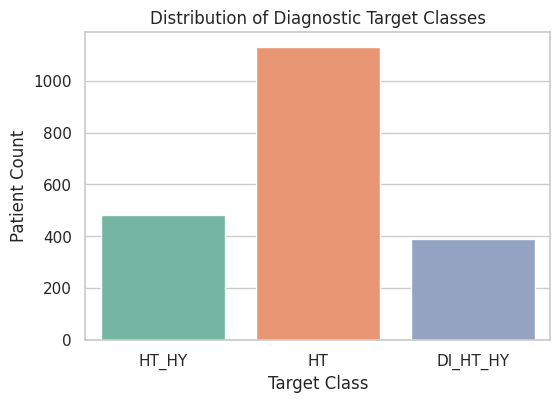

In [46]:
#Visualize class imbalance
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='target_class', hue='target_class', palette='Set2', legend=False)
plt.title('Distribution of Diagnostic Target Classes')
plt.xlabel('Target Class')
plt.ylabel('Patient Count')
plt.show()

In [47]:
#regression target
print("\nTarget regression analysis")
display(df['target_regression'].describe())


Target regression analysis


,target_regression
count,2000.000000
mean,132.253761
std,38.172917
min,80.000000
25%,100.000000
50%,130.000000
75%,156.000000
max,300.000000


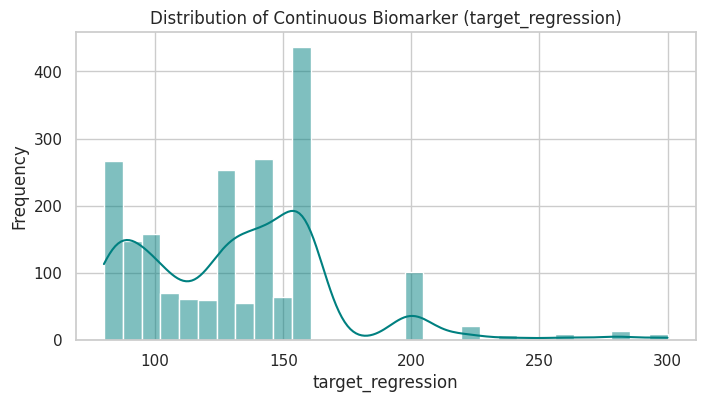

In [48]:
#Distribution of target regression
plt.figure(figsize=(8, 4))
sns.histplot(df['target_regression'], kde=True, color='teal', bins=30)
plt.title('Distribution of Continuous Biomarker (target_regression)')
plt.xlabel('target_regression')
plt.ylabel('Frequency')
plt.show()

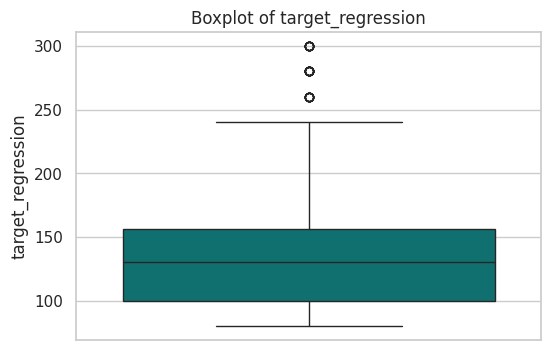

In [49]:
#Boxplot of target regression
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['target_regression'], color='teal')
plt.title('Boxplot of target_regression')
plt.ylabel('target_regression')
plt.show()

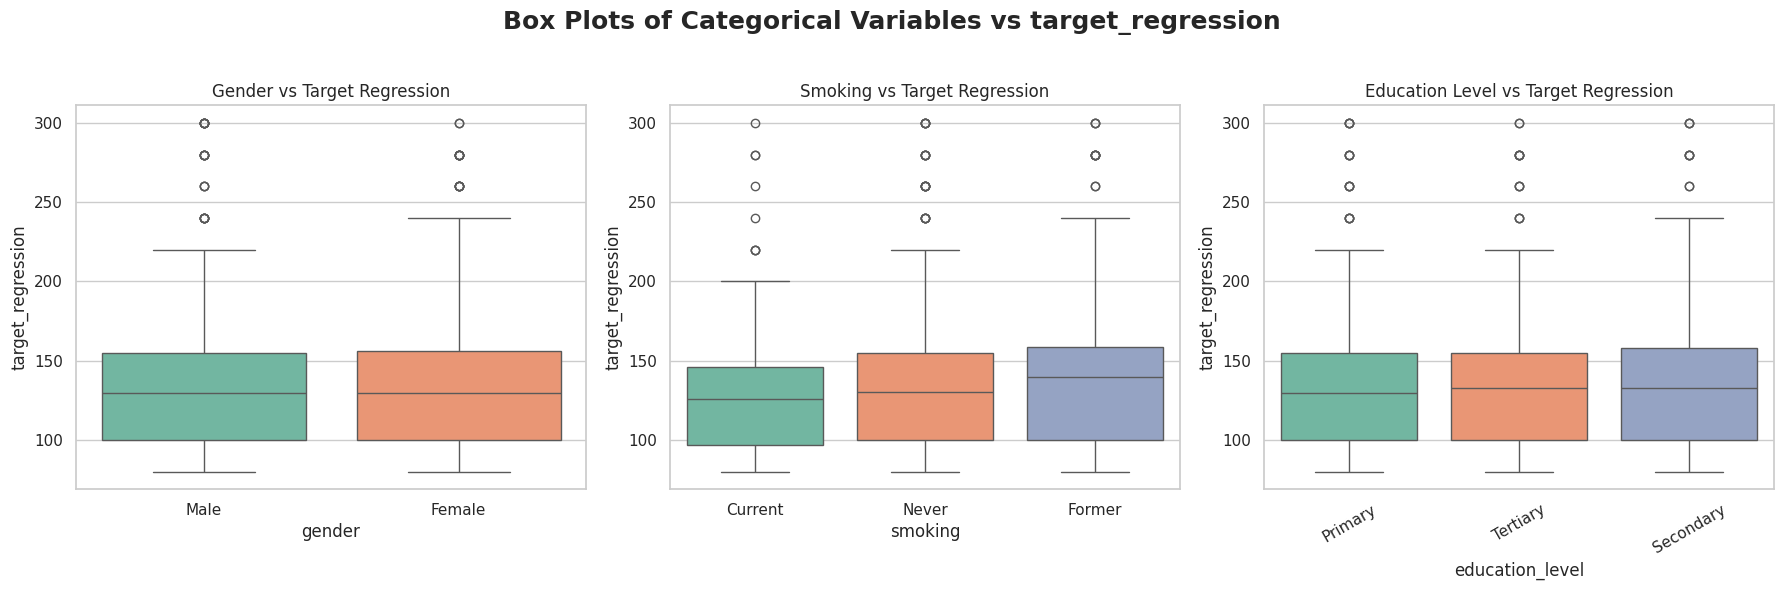

In [62]:
# Box plots for categorical variables vs target_regression
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Box Plots of Categorical Variables vs target_regression', fontsize=18, fontweight='bold')

sns.boxplot(x='gender', y='target_regression', hue='gender', data=df, ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('Gender vs Target Regression')

sns.boxplot(x='smoking', y='target_regression', hue='smoking', data=df, ax=axes[1], palette='Set2', legend=False)
axes[1].set_title('Smoking vs Target Regression')

sns.boxplot(x='education_level', y='target_regression', hue='education_level', data=df, ax=axes[2], palette='Set2', legend=False)
axes[2].set_title('Education Level vs Target Regression')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [51]:
# Mathematical outlier detection using the Interquartile Range (IQR) method for target_regression
Q1 = df['target_regression'].quantile(0.25)
Q3 = df['target_regression'].quantile(0.75)
IQR = Q3 - Q1

# Define threshold bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter rows that fall outside the bounds
outliers = df[(df['target_regression'] < lower_bound) | (df['target_regression'] > upper_bound)]

print(f"Lower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")
print(f"Number of outliers detected: {len(outliers)} out of 2000 records")

Lower bound: 16.00
Upper bound: 240.00
Number of outliers detected: 31 out of 2000 records


Data cleaning

In [52]:
# Identify constant or empty columns (zero variance or all unique/empty)
constant_cols = [col for col in df.columns if df[col].nunique() <= 1 or df[col].isna().all()]
print(f"Constant or empty columns to drop: {constant_cols}")

# Drop constant/empty columns
df_cleaned = df.drop(columns=constant_cols, errors='ignore')

# Select only numerical columns from our cleaned dataframe
numerical_df = df_cleaned.select_dtypes(include=[np.number])

# Calculate Pearson correlation with target_regression and sort by absolute value (strength)
target_corr = numerical_df.corr()['target_regression'].abs().sort_values(ascending=False)

# Create a comprehensive summary DataFrame
corr_summary = pd.DataFrame({
    'Feature': target_corr.index,
    'Correlation with target_regression': numerical_df.corr()['target_regression'][target_corr.index],
    'Absolute Correlation': target_corr.values
})

# Display top and bottom features
print("\nTop 10 features most correlated with target regression")
display(corr_summary.head(10))

print("\nBottom 5 features (weak correlation)")
display(corr_summary.tail(5))

# Automatically filter out features with extremely weak correlation close to 0
weak_features = target_corr[target_corr.abs() < 0.005].index.tolist()
print(f"\nZero correlation features to drop: {weak_features}")

# Drop them from the dataset
df_cleaned = df_cleaned.drop(columns=weak_features, errors='ignore')
print(f"Number of columns after dropping suspicious features: {df_cleaned.shape[1]}")

Constant or empty columns to drop: ['calcium_baseline']

Top 10 features most correlated with target regression


,Feature,Correlation with target_regression,Absolute Correlation
target_regression,target_regression,1.000000,1.000000
HbA1c_level,HbA1c_level,0.135789,0.135789
age_normalized,age_normalized,0.129170,0.129170
age,age,0.129170,0.129170
salt_intake,salt_intake,0.072770,0.072770
triglycerides,triglycerides,-0.058374,0.058374
hdl,hdl,-0.058175,0.058175
systolic_index,systolic_index,0.056257,0.056257
systolic_bp,systolic_bp,0.056257,0.056257
alcohol_intake,alcohol_intake,-0.050006,0.050006



Bottom 5 features (weak correlation)


,Feature,Correlation with target_regression,Absolute Correlation
blood_pressure,blood_pressure,-0.006767,0.006767
ldl,ldl,-0.006513,0.006513
crp_level,crp_level,-0.003465,0.003465
ldl_alternative,ldl_alternative,-0.000856,0.000856
sleep_hours,sleep_hours,-0.000009,0.000009



Zero correlation features to drop: ['crp_level', 'ldl_alternative', 'sleep_hours']
Number of columns after dropping suspicious features: 31


Multicollinearity and redundancy analisis

In [54]:
numerical_df_cleaned = df_cleaned.select_dtypes(include=[np.number])
corr_matrix = numerical_df_cleaned.corr()

# Find highly redundant pairs (correlation > 0.90 in upper triangle)
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
threshold = 0.90
redundant_pairs = []

for col in upper_tri.columns:
    high_corrs = upper_tri.index[upper_tri[col] > threshold].tolist()
    for row in high_corrs:
        redundant_pairs.append((row, col, corr_matrix.loc[row, col]))

print(f"\nRedundancy check (Threshold > {threshold})")
if redundant_pairs:
    for pair in redundant_pairs:
        print(f" • '{pair[0]}' <-> '{pair[1]}' (Correlation: {pair[2]:.2f})")
else:
    print("No highly redundant pairs found.")

# Explicit drop of confirmed scaled/redundant mirror variables
columns_to_drop_final = ['age_normalized', 'systolic_index']
df_cleaned = df_cleaned.drop(columns=columns_to_drop_final, errors='ignore')
print(f"Shape after dropping redundant features: {df_cleaned.shape}")


Redundancy check (Threshold > 0.9)
 • 'age' <-> 'age_normalized' (Correlation: 1.00)
 • 'systolic_bp' <-> 'systolic_index' (Correlation: 1.00)
Shape after dropping redundant features: (2000, 29)


##Feature engineering

In [55]:
# Generate domain-specific interaction features
df_cleaned['HbA1c_x_age'] = df_cleaned['HbA1c_level'] * df_cleaned['age']
df_cleaned['BMI_x_Triglycerides'] = df_cleaned['bmi'] * df_cleaned['triglycerides']
df_cleaned['Systolic_x_Salt'] = df_cleaned['systolic_bp'] * df_cleaned['salt_intake']

# Evaluate linear correlation of newly created interaction terms with target
interaction_features = ['HbA1c_x_age', 'BMI_x_Triglycerides', 'Systolic_x_Salt']
interaction_corr = df_cleaned[interaction_features + ['target_regression']].corr()['target_regression'].drop('target_regression')

display(interaction_corr)

,target_regression
HbA1c_x_age,0.197035
BMI_x_Triglycerides,-0.027668
Systolic_x_Salt,0.086085


Plot interaction correlations

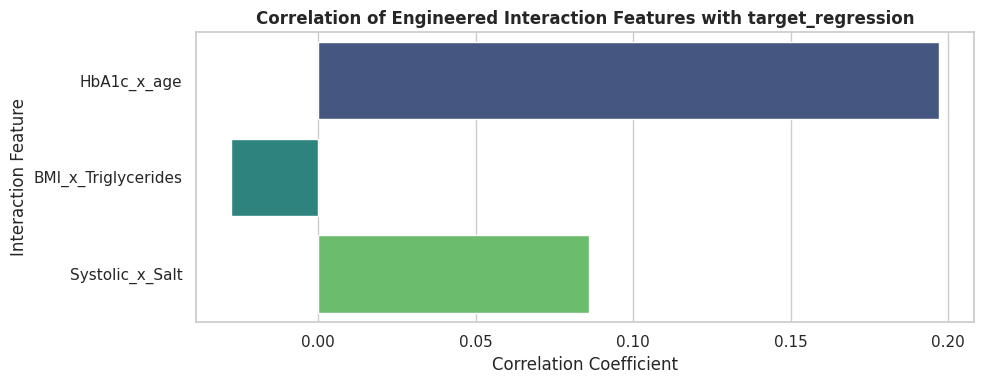

In [56]:
plt.figure(figsize=(10, 4))
sns.barplot(x=interaction_corr.values, y=interaction_corr.index, palette='viridis', hue=interaction_corr.index, legend=False)
plt.title('Correlation of Engineered Interaction Features with target_regression', fontsize=12, fontweight='bold')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Interaction Feature')
plt.tight_layout()
plt.show()

##Bivariate analysis

In [57]:
numerical_df = df.select_dtypes(include=[np.number])
exclude_cols = ['target_regression', 'target_class']

# Drop columns with zero variance (constant values) to avoid division by zero warnings
numerical_df = numerical_df.loc[:, numerical_df.std() > 0]

# Calculate Pearson correlation with target_regression and sort descending
correlations = numerical_df.drop(columns=exclude_cols, errors='ignore').corrwith(df['target_regression']).abs().sort_values(ascending=False)

# Filter out redundant/scaled features (e.g., containing 'normalized', 'baseline', 'index')
filtered_corrs = correlations[~correlations.index.str.contains('normalized|baseline|index', case=False, na=False)]

# Take top 4 distinct features
top_features = filtered_corrs.head(4).index.tolist()

print("Top 4 unique features with the strongest correlation to target_regression:")
for i, feat in enumerate(top_features, 1):
    corr_val = df[feat].corr(df['target_regression'])
    print(f"{i}. {feat} (Correlation: {corr_val:.2f})")

Top 4 unique features with the strongest correlation to target_regression:
1. HbA1c_level (Correlation: 0.14)
2. age (Correlation: 0.13)
3. salt_intake (Correlation: 0.07)
4. triglycerides (Correlation: -0.06)


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


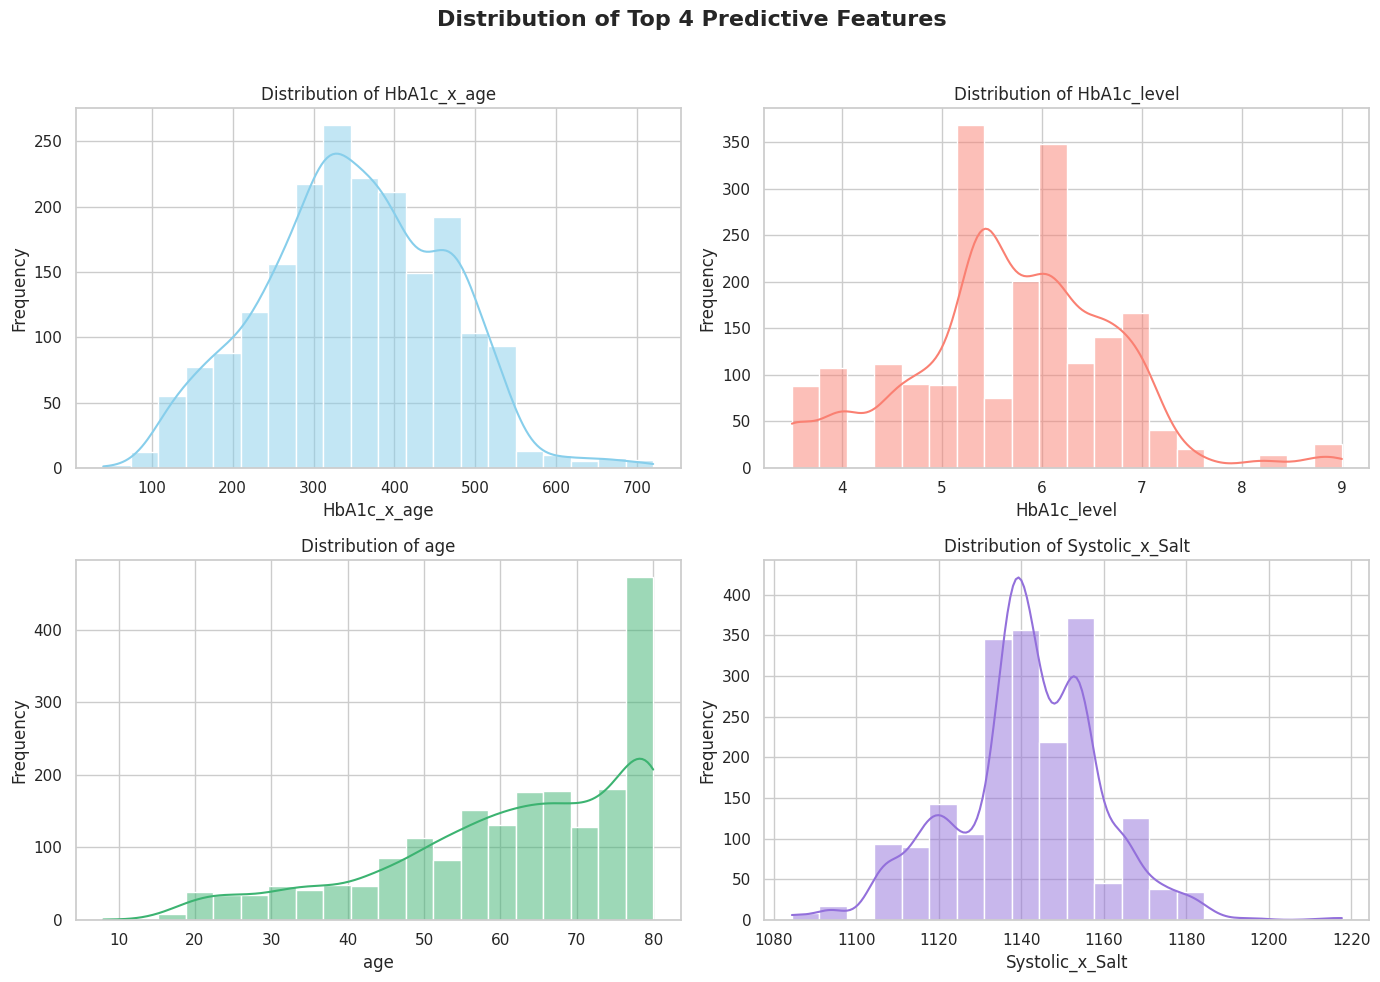

In [58]:
# Distribution of top 4 independent features
numerical_df_final = df_cleaned.select_dtypes(include=[np.number])
top_features_list = numerical_df_final.drop(columns=['target_regression', 'target_class'], errors='ignore') \
                                       .corrwith(df_cleaned['target_regression']).abs() \
                                       .sort_values(ascending=False).head(4).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Distribution of Top 4 Predictive Features', fontsize=16, fontweight='bold')
axes_flat = axes.flatten()
colors = ['skyblue', 'salmon', 'mediumseagreen', 'mediumpurple']

for i, feature in enumerate(top_features_list):
    sns.histplot(df_cleaned[feature], kde=True, bins=20, ax=axes_flat[i], color=colors[i])
    axes_flat[i].set_title(f'Distribution of {feature}')
    axes_flat[i].set_xlabel(feature)
    axes_flat[i].set_ylabel('Frequency')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

Relationship between target_class and target_regression

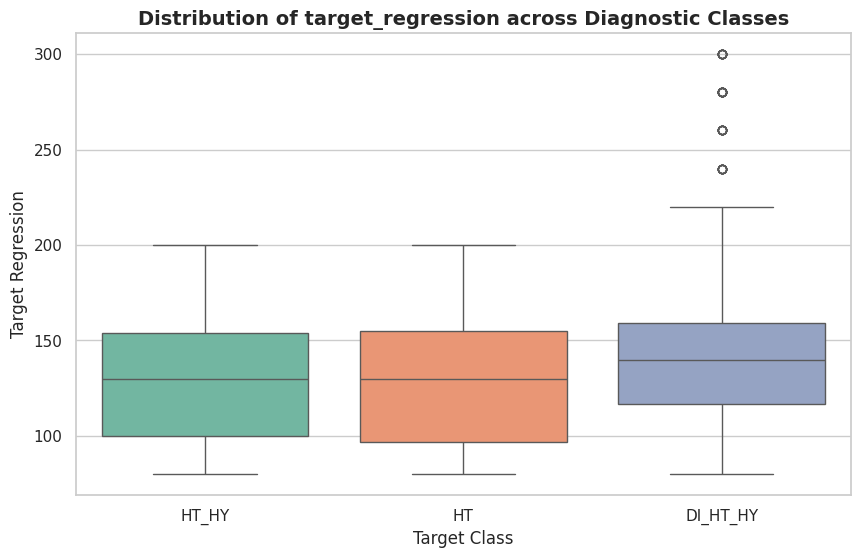

In [59]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='target_class', y='target_regression', hue='target_class', data=df_cleaned, palette='Set2', legend=False)
plt.title('Distribution of target_regression across Diagnostic Classes', fontsize=14, fontweight='bold')
plt.xlabel('Target Class')
plt.ylabel('Target Regression')
plt.show()

Scatter plots for key continuous predictors vs target_regression

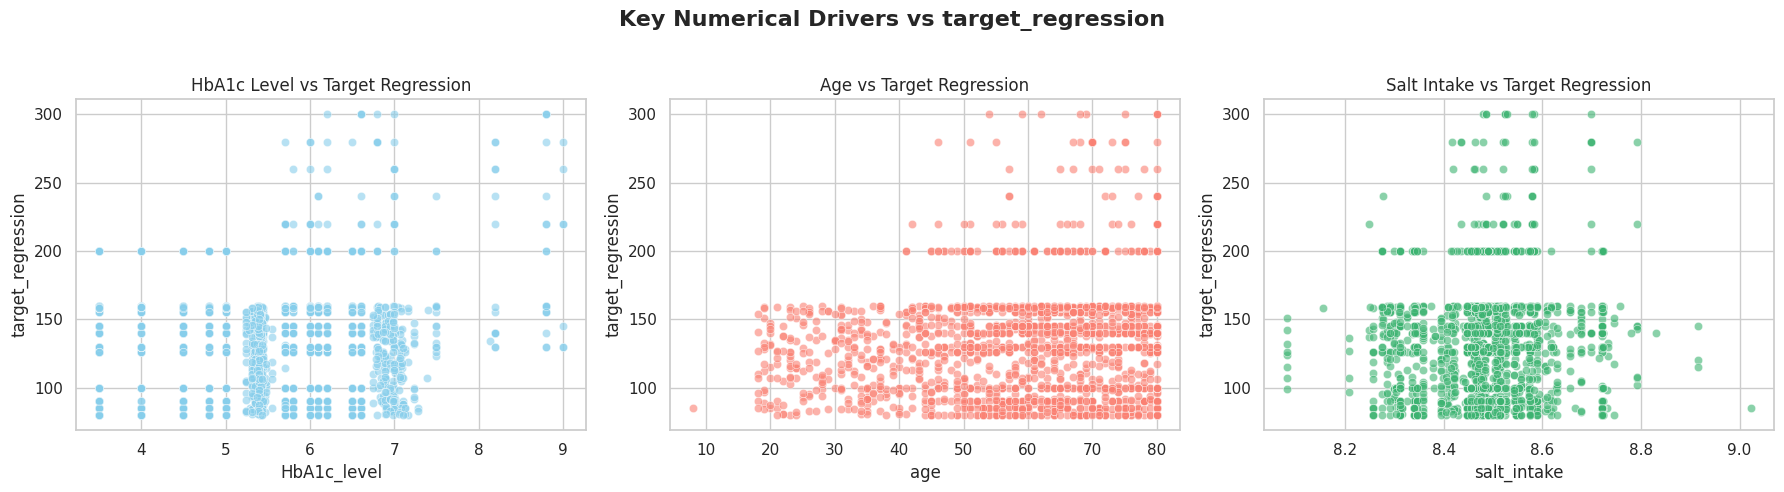

In [60]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Key Numerical Drivers vs target_regression', fontsize=16, fontweight='bold')

sns.scatterplot(x='HbA1c_level', y='target_regression', data=df_cleaned, ax=axes[0], color='skyblue', alpha=0.6)
axes[0].set_title('HbA1c Level vs Target Regression')

sns.scatterplot(x='age', y='target_regression', data=df_cleaned, ax=axes[1], color='salmon', alpha=0.6)
axes[1].set_title('Age vs Target Regression')

sns.scatterplot(x='salt_intake', y='target_regression', data=df_cleaned, ax=axes[2], color='mediumseagreen', alpha=0.6)
axes[2].set_title('Salt Intake vs Target Regression')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

##Correlation heatmap

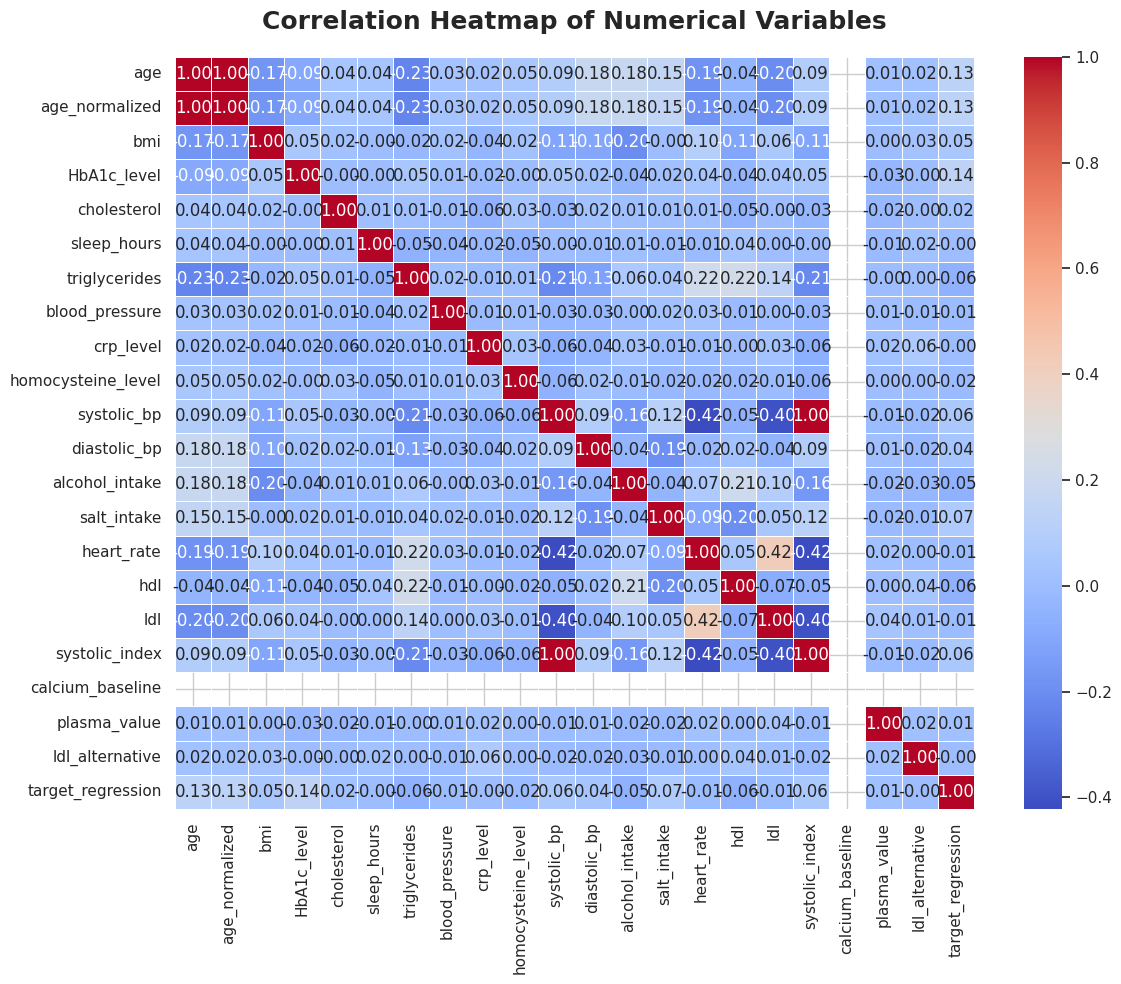

In [61]:
# Select only numerical columns
numerical_df = df.select_dtypes(include=[np.number])

# Calculate the correlation matrix
corr_matrix = numerical_df.corr()

# Plot the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5, cbar=True)
plt.title('Correlation Heatmap of Numerical Variables', fontsize=18, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

### Conclusions and Feature Recommendations

After completing the Exploratory Data Analysis (EDA) and data cleaning process for our dataset, we can draw the following key conclusions and recommendations:

1. **Data Quality & Completeness:**
   * The dataset is clean, with **no missing values** or duplicate patient rows found.
   * Empty or constant features (such as `calcium_baseline`) were successfully removed as they carried no analytical value.

2. **Key Predictive Features:**
   * Based on our correlation analysis with the target variables, features like **`HbA1c_level`**, **`age`**, and **`salt_intake`** show the strongest relationships and will serve as primary predictors for our models.

3. **Multicollinearity & Redundancy:**
   * The correlation matrix revealed perfect linear dependency (correlation of 1.00) between pairs of variables: `age` vs `age_normalized`, and `systolic_bp` vs `systolic_index`.
   * **Recommendation:** To prevent multicollinearity issues in linear and logistic regression models, we dropped the redundant duplicate columns (`age_normalized` and `systolic_index`), keeping only their original counterparts.

4. **Final Dataset Status:**
   * The dataset is fully optimized, cleaned, and ready for model building and training in Part 2.